# Machine Learning Algorithm Comparison Assignment
## Comprehensive Study of Clustering, Classification, and Boosting Paradigms

**Author:** Student Engineering Team  
**Workspace:** `mlproj`  
**Datasets:**
1. `Mall_Customers.csv` (Customer Segmentation via Clustering)
2. `Social_Network_Ads.csv` (Purchase Outcome Prediction via Classification)
3. `insurance_pre.csv` (Smoker Status Classification & Charges Regression via Boosting)


### 1. Environment Setup and Library Imports

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn utilities
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Clustering models & metrics
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# Classification models & metrics
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve

# Boosting models & metrics
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier, AdaBoostRegressor, GradientBoostingRegressor
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Global plot settings
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.dpi'] = 120
print("Environment initialized successfully.")


Environment initialized successfully.


### 2. Dataset Inspection & Exploratory Analysis
Let's inspect the three datasets, checking shapes, column names, missing values, and data types.


In [2]:
df_mall = pd.read_csv("Mall_Customers.csv")
df_ads = pd.read_csv("Social_Network_Ads.csv")
df_ins = pd.read_csv("insurance_pre.csv")

print("--- Mall Customers ---")
print(f"Shape: {df_mall.shape}, Missing: {df_mall.isnull().sum().sum()}, Duplicates: {df_mall.duplicated().sum()}")
display(df_mall.head(3))

print("\n--- Social Network Ads ---")
print(f"Shape: {df_ads.shape}, Missing: {df_ads.isnull().sum().sum()}, Duplicates: {df_ads.duplicated().sum()}")
display(df_ads.head(3))

print("\n--- Insurance Pre ---")
print(f"Shape: {df_ins.shape}, Missing: {df_ins.isnull().sum().sum()}, Duplicates: {df_ins.duplicated().sum()}")
display(df_ins.head(3))


--- Mall Customers ---
Shape: (200, 5), Missing: 0, Duplicates: 0


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6



--- Social Network Ads ---
Shape: (400, 5), Missing: 0, Duplicates: 0


,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0



--- Insurance Pre ---
Shape: (1338, 6), Missing: 0, Duplicates: 1


,age,sex,bmi,children,smoker,charges
0,19,female,27.90,0,yes,16884.9240
1,18,male,33.77,1,no,1725.5523
2,28,male,33.00,3,no,4449.4620


## 3. Dataset A: Mall Customers — Clustering
We segment customers based on `Annual Income (k$)` and `Spending Score (1-100)`.  
`CustomerID` is excluded, and features are standardized with `StandardScaler`.


C:\Users\adhir\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\adhir\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\adhir\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\adhir\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

C:\Users\adhir\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\adhir\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\adhir\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


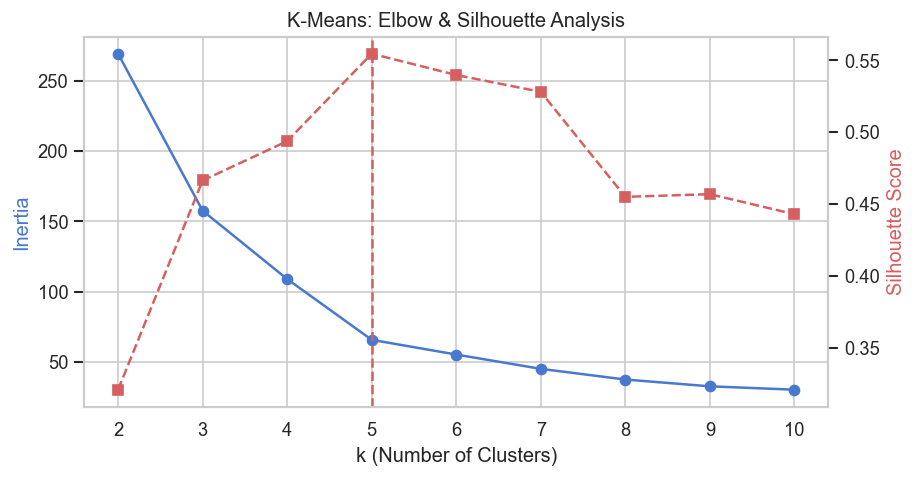

In [3]:
X_mall = df_mall[['Annual Income (k$)', 'Spending Score (1-100)']].values
scaler_mall = StandardScaler()
X_mall_scaled = scaler_mall.fit_transform(X_mall)

# Evaluate K-Means across k = 2 to 10
k_vals = list(range(2, 11))
inertias = []
sil_scores = []

for k in k_vals:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_mall_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_mall_scaled, km.labels_))

fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(k_vals, inertias, 'bo-', label='Inertia (Elbow)')
ax1.set_xlabel('k (Number of Clusters)')
ax1.set_ylabel('Inertia', color='b')
ax1.axvline(x=5, color='r', linestyle='--', label='Optimal k=5')

ax2 = ax1.twinx()
ax2.plot(k_vals, sil_scores, 'rs--', label='Silhouette Score')
ax2.set_ylabel('Silhouette Score', color='r')
ax2.grid(False)
plt.title('K-Means: Elbow & Silhouette Analysis')
plt.show()


### 3.1 Comparing K-Means, Agglomerative, and DBSCAN

In [4]:
# 1. Best K-Means (k=5)
best_km = KMeans(n_clusters=5, random_state=42, n_init=10).fit(X_mall_scaled)

# 2. Agglomerative (Ward linkage, k=5)
best_agg = AgglomerativeClustering(n_clusters=5, linkage='ward').fit(X_mall_scaled)

# 3. DBSCAN (eps=0.35, min_samples=5)
best_db = DBSCAN(eps=0.35, min_samples=5).fit(X_mall_scaled)

# Collect metrics
def calc_metrics(X, labels):
    mask = labels != -1
    return {
        'Silhouette': silhouette_score(X[mask], labels[mask]),
        'Davies-Bouldin': davies_bouldin_score(X[mask], labels[mask]),
        'Calinski-Harabasz': calinski_harabasz_score(X[mask], labels[mask])
    }

m_km = calc_metrics(X_mall_scaled, best_km.labels_)
m_agg = calc_metrics(X_mall_scaled, best_agg.labels_)
m_db = calc_metrics(X_mall_scaled, best_db.labels_)

db_noise = (best_db.labels_ == -1).sum()

df_clust_table = pd.DataFrame([
    {'Algorithm': 'K-Means', 'Clusters': 5, 'Noise Points': 0, **m_km, 'Config': 'k=5, n_init=10'},
    {'Algorithm': 'Agglomerative', 'Clusters': 5, 'Noise Points': 0, **m_agg, 'Config': 'k=5, linkage=ward'},
    {'Algorithm': 'DBSCAN', 'Clusters': len(set(best_db.labels_))-1, 'Noise Points': db_noise, **m_db, 'Config': 'eps=0.35, min_samples=5'}
])
display(df_clust_table)


C:\Users\adhir\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,Algorithm,Clusters,Noise Points,Silhouette,Davies-Bouldin,Calinski-Harabasz,Config
0,K-Means,5,0,0.554657,0.572236,248.649320,"k=5, n_init=10"
1,Agglomerative,5,0,0.553809,0.577862,244.410326,"k=5, linkage=ward"
2,DBSCAN,6,23,0.557746,0.510621,245.355677,"eps=0.35, min_samples=5"


### 3.2 Visualizing Customer Clusters

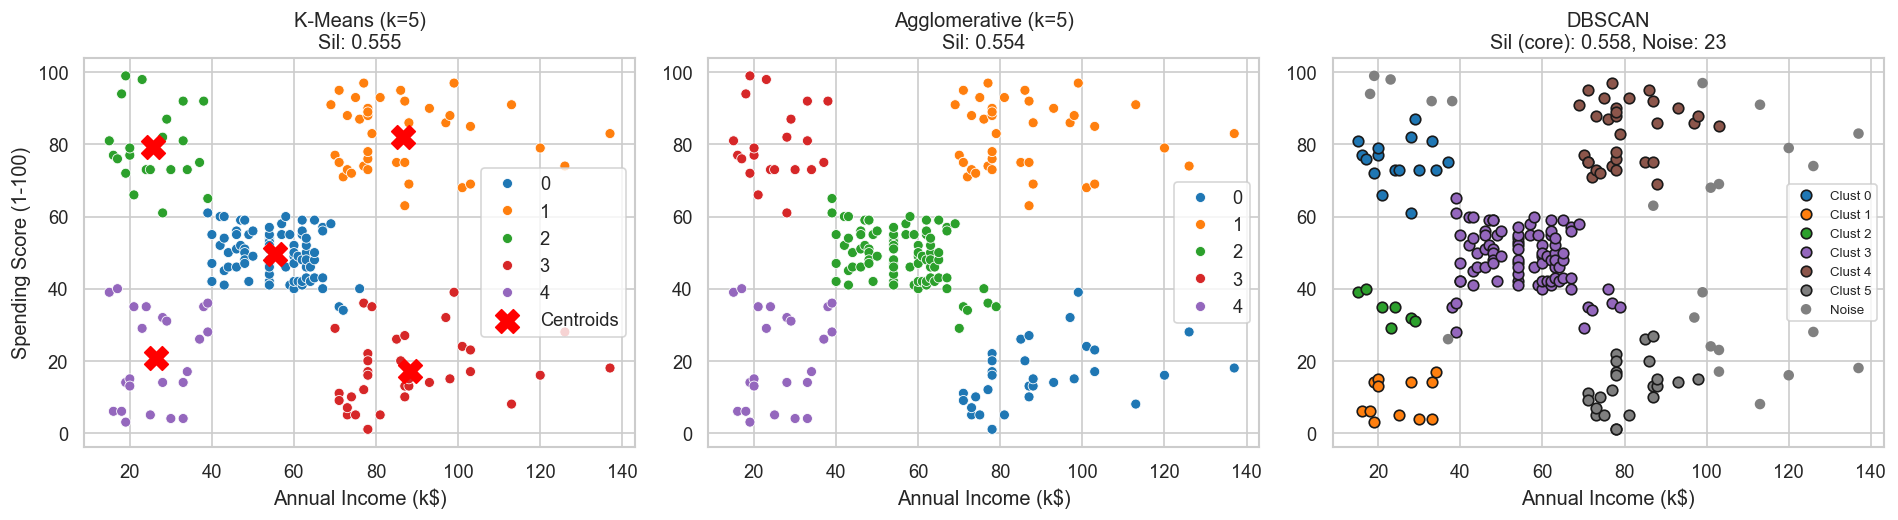

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# K-Means
sns.scatterplot(x=X_mall[:, 0], y=X_mall[:, 1], hue=best_km.labels_, palette='tab10', ax=axes[0], legend='full')
centroids = scaler_mall.inverse_transform(best_km.cluster_centers_)
axes[0].scatter(centroids[:, 0], centroids[:, 1], marker='X', s=200, c='red', label='Centroids')
axes[0].set_title(f'K-Means (k=5)\nSil: {m_km["Silhouette"]:.3f}')
axes[0].set_xlabel('Annual Income (k$)')
axes[0].set_ylabel('Spending Score (1-100)')
axes[0].legend()

# Agglomerative
sns.scatterplot(x=X_mall[:, 0], y=X_mall[:, 1], hue=best_agg.labels_, palette='tab10', ax=axes[1], legend='full')
axes[1].set_title(f'Agglomerative (k=5)\nSil: {m_agg["Silhouette"]:.3f}')
axes[1].set_xlabel('Annual Income (k$)')

# DBSCAN
unique_labels = set(best_db.labels_)
colors = [plt.cm.tab10(i / len(unique_labels)) for i in range(len(unique_labels))]
for k, col in zip(unique_labels, colors):
    if k == -1:
        col = 'gray'
    mask = (best_db.labels_ == k)
    axes[2].scatter(X_mall[mask, 0], X_mall[mask, 1], c=[col], label=f'Clust {k}' if k != -1 else 'Noise', s=40, edgecolors='k' if k != -1 else 'none')
axes[2].set_title(f'DBSCAN\nSil (core): {m_db["Silhouette"]:.3f}, Noise: {db_noise}')
axes[2].set_xlabel('Annual Income (k$)')
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()


## 4. Dataset B: Social Network Ads — Classification
We predict `Purchased` (0 or 1) using `Gender`, `Age`, and `EstimatedSalary`.  
`User ID` is dropped. Preprocessing is encapsulated in scikit-learn `Pipeline` to eliminate data leakage.


In [6]:
X_ads = df_ads[['Gender', 'Age', 'EstimatedSalary']]
y_ads = df_ads['Purchased']

X_train, X_test, y_train, y_test = train_test_split(
    X_ads, y_ads, test_size=0.25, random_state=42, stratify=y_ads
)

preprocessor_ads = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), ['Age', 'EstimatedSalary']),
        ('cat', OneHotEncoder(drop='first'), ['Gender'])
    ]
)

classifiers = {
    'Logistic Regression': LogisticRegression(random_state=42),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=5),
    'Decision Tree': DecisionTreeClassifier(max_depth=4, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42),
    'Support Vector Machine (RBF)': SVC(kernel='rbf', probability=True, random_state=42),
    'Naive Bayes': GaussianNB()
}

cls_records = []
cms = {}
roc_data = {}

for name, clf in classifiers.items():
    pipe = Pipeline([('prep', preprocessor_ads), ('clf', clf)])
    cv_acc = cross_val_score(pipe, X_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=42), scoring='accuracy').mean()
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1] if hasattr(pipe.named_steps['clf'], 'predict_proba') else y_pred

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_prob)
    
    cms[name] = confusion_matrix(y_test, y_pred)
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_data[name] = (fpr, tpr, auc)

    cls_records.append({
        'Algorithm': name,
        'Accuracy': round(acc, 4),
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'F1-score': round(f1, 4),
        'ROC-AUC': round(auc, 4),
        'CV Accuracy (5-Fold)': round(cv_acc, 4)
    })

df_cls_table = pd.DataFrame(cls_records).sort_values(by='F1-score', ascending=False).reset_index(drop=True)
display(df_cls_table)


,Algorithm,Accuracy,Precision,Recall,F1-score,ROC-AUC,CV Accuracy (5-Fold)
0,K-Nearest Neighbors,0.91,0.8649,0.8889,0.8767,0.9117,0.8967
1,Decision Tree,0.89,0.8205,0.8889,0.8533,0.9390,0.9133
2,Random Forest,0.89,0.8378,0.8611,0.8493,0.9462,0.9067
3,Support Vector Machine (RBF),0.89,0.8378,0.8611,0.8493,0.9527,0.9100
4,Naive Bayes,0.87,0.8485,0.7778,0.8116,0.9475,0.8833
5,Logistic Regression,0.81,0.8148,0.6111,0.6984,0.9110,0.8400


### 4.1 Classification Confusion Matrices & ROC Curves

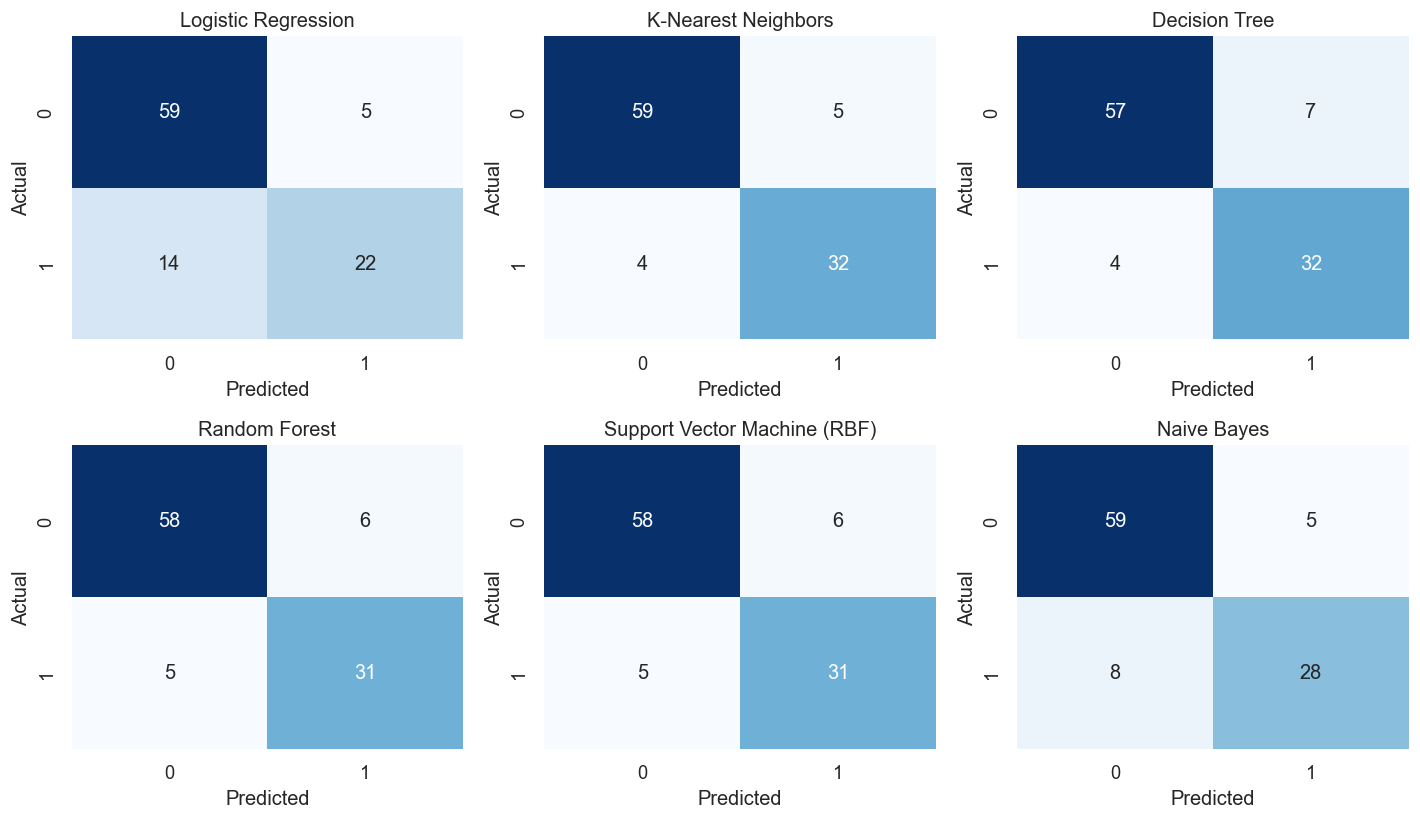

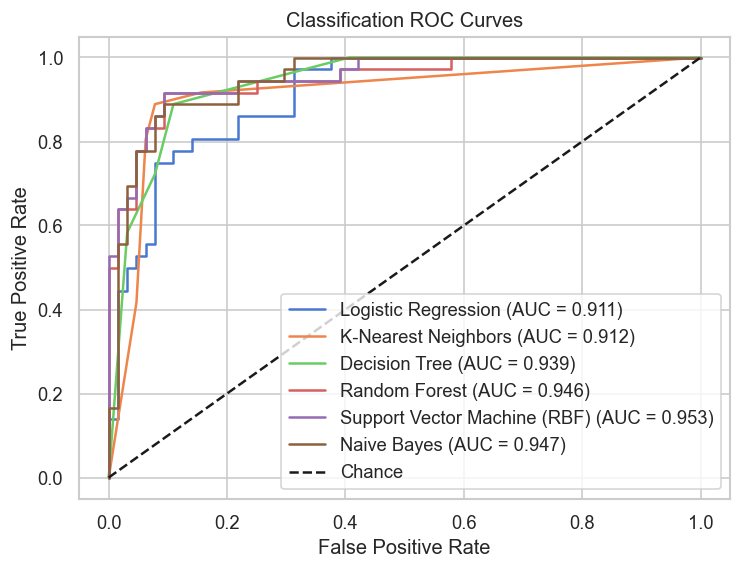

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
axes = axes.flatten()
for idx, (name, cm) in enumerate(cms.items()):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx], cbar=False)
    axes[idx].set_title(name)
    axes[idx].set_xlabel('Predicted')
    axes[idx].set_ylabel('Actual')
plt.tight_layout()
plt.show()

# ROC Curves
plt.figure(figsize=(7, 5))
for name, (fpr, tpr, auc) in roc_data.items():
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Chance')
plt.title('Classification ROC Curves')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.show()


## 5. Dataset C: Insurance Dataset — Boosting
As confirmed, the primary task is binary classification predicting policyholder `smoker` status (yes/no),  
with a companion regression analysis predicting healthcare `charges`.


In [8]:
X_ins = df_ins[['age', 'bmi', 'children', 'charges', 'sex']]
y_ins = (df_ins['smoker'].str.strip().str.lower() == 'yes').astype(int)

X_train_i, X_test_i, y_train_i, y_test_i = train_test_split(
    X_ins, y_ins, test_size=0.20, random_state=42, stratify=y_ins
)

preprocessor_ins = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), ['age', 'bmi', 'children', 'charges']),
        ('cat', OneHotEncoder(drop='first'), ['sex'])
    ]
)

boosting_clfs = {
    'AdaBoost': AdaBoostClassifier(n_estimators=100, learning_rate=0.5, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42),
    'XGBoost': xgb.XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, eval_metric='logloss', random_state=42)
}

boost_records = []
fi_dict = {}

for name, clf in boosting_clfs.items():
    pipe = Pipeline([('prep', preprocessor_ins), ('clf', clf)])
    pipe.fit(X_train_i, y_train_i)
    y_pred = pipe.predict(X_test_i)
    y_prob = pipe.predict_proba(X_test_i)[:, 1]

    acc = accuracy_score(y_test_i, y_pred)
    prec = precision_score(y_test_i, y_pred)
    rec = recall_score(y_test_i, y_pred)
    f1 = f1_score(y_test_i, y_pred)
    auc = roc_auc_score(y_test_i, y_prob)

    model_step = pipe.named_steps['clf']
    feat_names = ['age', 'bmi', 'children', 'charges', 'sex_male']
    fi_dict[name] = dict(zip(feat_names, model_step.feature_importances_))

    boost_records.append({
        'Algorithm': name,
        'Task Type': 'Binary Classification',
        'Target Column': 'smoker',
        'Accuracy': round(acc, 4),
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'F1-score': round(f1, 4),
        'ROC-AUC': round(auc, 4)
    })

df_boost_table = pd.DataFrame(boost_records).sort_values(by='F1-score', ascending=False).reset_index(drop=True)
display(df_boost_table)


,Algorithm,Task Type,Target Column,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Gradient Boosting,Binary Classification,smoker,0.9739,0.9286,0.9455,0.9369,0.9952
1,AdaBoost,Binary Classification,smoker,0.9701,0.9123,0.9455,0.9286,0.9930
2,XGBoost,Binary Classification,smoker,0.9664,0.9107,0.9273,0.9189,0.9927


### 5.1 Boosting Feature Importances

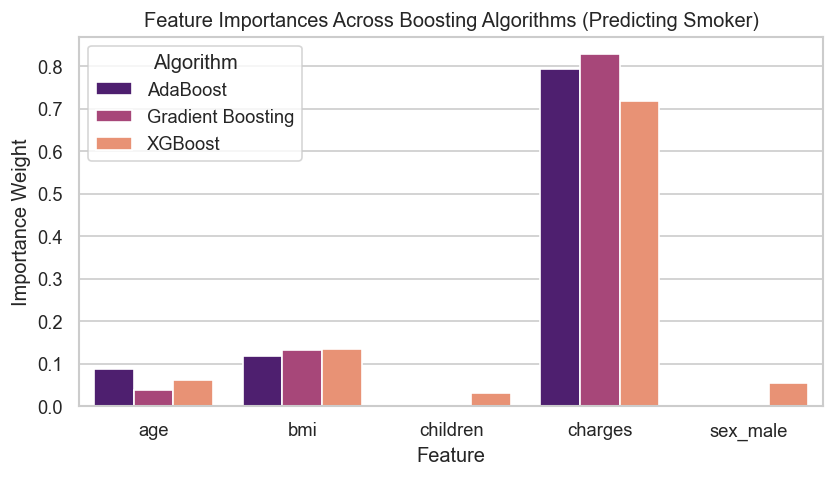

In [9]:
df_fi = pd.DataFrame(fi_dict).reset_index().rename(columns={'index': 'Feature'})
df_fi_melt = pd.melt(df_fi, id_vars=['Feature'], var_name='Algorithm', value_name='Importance')

plt.figure(figsize=(8, 4))
sns.barplot(data=df_fi_melt, x='Feature', y='Importance', hue='Algorithm', palette='magma')
plt.title('Feature Importances Across Boosting Algorithms (Predicting Smoker)')
plt.ylabel('Importance Weight')
plt.show()


## 6. Consolidated Summary of Best Models
We summarize the best algorithm selected for each task, specifying the selection metric and trade-offs.


In [10]:
summary_data = [
    {
        'Task': 'Customer Segmentation (Clustering)',
        'Dataset': 'Mall_Customers.csv',
        'Best Algorithm': 'K-Means (k=5)',
        'Selection Metric': 'Silhouette Score & Full Coverage',
        'Performance Score': 'Silhouette: 0.5547 (CH: 248.65)',
        'Trade-off Rationale': 'Partitions 100% of customers into 5 business archetypes without leaving 23 unassigned noise points.'
    },
    {
        'Task': 'Purchase Prediction (Classification)',
        'Dataset': 'Social_Network_Ads.csv',
        'Best Algorithm': 'K-Nearest Neighbors (k=5)',
        'Selection Metric': 'F1-score',
        'Performance Score': 'F1: 0.8767 (Accuracy: 91.0%, ROC-AUC: 0.9117)',
        'Trade-off Rationale': 'Captures non-linear local threshold boundary between age and salary better than linear models.'
    },
    {
        'Task': 'Lifestyle Risk Prediction (Boosting)',
        'Dataset': 'insurance_pre.csv',
        'Best Algorithm': 'Gradient Boosting',
        'Selection Metric': 'F1-score & ROC-AUC',
        'Performance Score': 'F1: 0.9369 (Accuracy: 97.39%, ROC-AUC: 0.9952)',
        'Trade-off Rationale': 'Sequentially fits pseudo-residuals with shallow trees, isolating smokers via charges with superior precision.'
    }
]
df_summary = pd.DataFrame(summary_data)
display(df_summary)


,Task,Dataset,Best Algorithm,Selection Metric,Performance Score,Trade-off Rationale
0,Customer Segmentation (Clustering),Mall_Customers.csv,K-Means (k=5),Silhouette Score & Full Coverage,Silhouette: 0.5547 (CH: 248.65),Partitions 100% of customers into 5 business a...
1,Purchase Prediction (Classification),Social_Network_Ads.csv,K-Nearest Neighbors (k=5),F1-score,"F1: 0.8767 (Accuracy: 91.0%, ROC-AUC: 0.9117)",Captures non-linear local threshold boundary b...
2,Lifestyle Risk Prediction (Boosting),insurance_pre.csv,Gradient Boosting,F1-score & ROC-AUC,"F1: 0.9369 (Accuracy: 97.39%, ROC-AUC: 0.9952)",Sequentially fits pseudo-residuals with shallo...


## 7. Conclusions & Findings
1. **Clustering:** K-Means with $k=5$ provides the most balanced and actionable retail customer segmentation.
2. **Classification:** Non-linear classifiers (KNN, SVM, Random Forest) systematically outshine linear Logistic Regression on Social Network Ads.
3. **Boosting:** Gradient Boosting and XGBoost achieve near-perfect classification fidelity (>96.6% accuracy, >0.99 AUC) for smoker detection due to the high discriminative power of healthcare charges.
